# Peter and the wolf: Q-learning and the resource-world assignment

Adapt the lesson's four cardinal actions, tabular values, epsilon-greedy
exploration, and Bellman update. First reproduce the apple-seeking task on
a fixed five-by-five board. Then change the objective and state for the
assignment. The shared [update](../qlearning.py) and [world rules](../world.py)
have focused tests. The original curriculum and its drawing module are unchanged.

In [1]:
import sys
sys.path.insert(0,'..')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython.display import display
from qlearning import update_q
import world
from world import simple_step, walk

rng=np.random.default_rng(42)
assert simple_step((0,0),1)[3]=='won'
assert simple_step((0,1),1)[3]=='lost'
q_simple=np.zeros((5,5,4))
base_training=[]
for episode in range(5000):
    state=world.STARTS[int(rng.integers(len(world.STARTS)))]
    epsilon=max(0.05,0.9*(1-episode/5000))
    total=0
    for _ in range(100):
        action=int(rng.integers(4)) if rng.random()<epsilon else int(np.argmax(q_simple[state]))
        next_state,reward,done,outcome=simple_step(state,action)
        update_q(q_simple,state,action,reward,next_state,done,0.3,0.95)
        state=next_state
        total+=reward
        if done: break
    base_training.append(total)

## Controlled comparison with a random walk

Give both policies the same pre-generated starting positions. Keep the
random-walk implementation and report failures and time limits separately.
The comparison concerns this board, not transfer to an unseen world.

In [2]:
test_rng=np.random.default_rng(200000)
test_starts=[world.STARTS[index] for index in test_rng.integers(len(world.STARTS),size=500)]
def evaluate_world(q,resource,random_policy):
    generator=np.random.default_rng(300000)
    records=[]
    for episode,start in enumerate(test_starts):
        state=(*start,6,0,3) if resource else start
        outcome='timeout'
        for count in range(1,101):
            action=int(generator.integers(4)) if random_policy else int(np.argmax(q[state]))
            next_state,reward,done,outcome=(world.step(state,action) if resource else simple_step(state,action))
            state=next_state
            if done: break
        if not done: outcome='timeout'
        records.append({'episode':episode,'start_x':start[0],'start_y':start[1],
                        'outcome':outcome,'steps':count})
    return pd.DataFrame(records)

simple_random=evaluate_world(q_simple,False,True)
simple_learned=evaluate_world(q_simple,False,False)
base_summary=pd.DataFrame([
    {'policy':name,'won':int(frame.outcome.eq('won').sum()),'lost':int(frame.outcome.eq('lost').sum()),
     'timeout':int(frame.outcome.eq('timeout').sum()),'mean_steps':frame.steps.mean()}
    for name,frame in [('Random walk',simple_random),('Q-learning',simple_learned)]
])
display(base_summary)
assert simple_learned.outcome.eq('won').mean()>simple_random.outcome.eq('won').mean()
base_summary.to_csv('apple-world-results.csv',index=False)

,policy,won,lost,timeout,mean_steps
0,Random walk,182,318,0,7.198
1,Q-learning,500,0,0,2.414


## Walk challenges: a move limit and no revisits

**Task 1:** `walk` takes at most 100 moves by default. The returned path also
contains its starting cell, so moves are `len(path) - 1`. A move-limit exit
is reported as `timeout`, separately from reaching an apple or a hazard.
The focused test forces 100 left-wall attempts to verify that even an
endlessly repeated action stops at the cap; ordinary random games usually
reach a terminal cell sooner.

**Task 2:** with `avoid_revisits=True`, choose uniformly among actions whose
resulting destination has not been visited. This also removes wall attempts,
which keep the current position. When no such destination remains, report
`trapped` instead of looping or drawing from an empty list. Hazardous cells
are still possible destinations: avoiding revisits does not teach the policy
where apples, water, or the wolf are.

Compare the two walk variants on the same 500 starts with episode seeds
400000–400499. This is a separate experiment from the earlier Q-learning
comparison; its generator is reset per episode for both variants.


In [3]:
walk_records = []
for avoid_revisits in (False, True):
    for episode, start in enumerate(test_starts):
        path, outcome = walk(
            start, np.random.default_rng(400000 + episode),
            max_steps=100, avoid_revisits=avoid_revisits,
        )
        assert len(path) - 1 <= 100
        if avoid_revisits:
            assert len(path) == len(set(path))
        walk_records.append({
            'policy': 'No revisits' if avoid_revisits else 'Random walk',
            'episode': episode, 'start_x': start[0], 'start_y': start[1],
            'outcome': outcome, 'steps': len(path) - 1,
            'revisited': len(path) != len(set(path)), 'path': path,
        })
walk_episodes = pd.DataFrame(walk_records)
walk_summary = pd.DataFrame([{
    'policy': name, 'won': int(frame.outcome.eq('won').sum()),
    'lost': int(frame.outcome.eq('lost').sum()),
    'trapped': int(frame.outcome.eq('trapped').sum()),
    'timeout': int(frame.outcome.eq('timeout').sum()),
    'mean_steps': frame.steps.mean(),
    'episodes_with_revisits': int(frame.revisited.sum()),
} for name, frame in walk_episodes.groupby('policy', sort=False)])
assert (walk_summary[['won', 'lost', 'trapped', 'timeout']].sum(axis=1) == 500).all()
display(walk_summary)
trapped = walk_episodes.loc[walk_episodes.outcome.eq('trapped')]
assert not trapped.empty
print('Example trapped path:', trapped.iloc[0]['path'])
walk_episodes.to_csv('walk-challenge-episodes.csv', index=False)
walk_summary.to_csv('walk-challenge-results.csv', index=False)


,policy,won,lost,trapped,timeout,mean_steps,episodes_with_revisits
0,Random walk,183,317,0,0,6.768,323
1,No revisits,155,328,17,0,3.202,0


Example trapped path: [(1, 4), (1, 3), (0, 3), (0, 4)]


## Assignment: a more realistic world

State is `(x, y, energy, fatigue, remaining_apple_mask)`. Every attempted
move costs one energy and adds one fatigue. An unconsumed apple restores
six energy, capped at twelve. Entering a tree or grass rest square removes
four fatigue. Cell effects occur after movement and before checking
exhaustion. Apples disappear after one use; the mask makes that part of
the state observable and Markovian.

Zero energy, fatigue eight, or water ends the game in a loss. Reaching the
wolf wins only with energy at least five and fatigue at most four after
movement. Other encounters with the wolf lose. Rewards are +30 for victory,
-20 for a loss, -0.1 per continuing move, and an extra -2 for a wall attempt.
Four movement actions suffice: resting happens when entering a rest square.

In [4]:
rng=np.random.default_rng(43)
q=np.zeros((5,5,13,9,4,4))
resource_training=[]
for episode in range(25000):
    position=world.STARTS[int(rng.integers(len(world.STARTS)))]
    state=(*position,6,0,3)
    epsilon=max(0.03,1-episode/20000)
    total=0
    for _ in range(100):
        action=int(rng.integers(4)) if rng.random()<epsilon else int(np.argmax(q[state]))
        next_state,reward,done,outcome=world.step(state,action)
        update_q(q,state,action,reward,next_state,done,0.3,0.95)
        state=next_state
        total+=reward
        if done: break
    resource_training.append(total)
random_results=evaluate_world(q,True,True)
learned_results=evaluate_world(q,True,False)
summary=pd.DataFrame([
    {'policy':name,'won':int(frame.outcome.eq('won').sum()),'lost':int(frame.outcome.eq('lost').sum()),
     'timeout':int(frame.outcome.eq('timeout').sum()),'win_rate':frame.outcome.eq('won').mean(),
     'mean_steps':frame.steps.mean()}
    for name,frame in [('Random walk',random_results),('Q-learning',learned_results)]
])
display(summary)
assert learned_results.outcome.eq('won').mean()>random_results.outcome.eq('won').mean()+0.2
summary.to_csv('resource-world-results.csv',index=False)
random_results.assign(policy='random').to_csv('resource-random-episodes.csv',index=False)
learned_results.assign(policy='learned').to_csv('resource-learned-episodes.csv',index=False)
np.savez_compressed('resource-policy.npz',q=q)

,policy,won,lost,timeout,win_rate,mean_steps
0,Random walk,16,484,0,0.032,4.996
1,Q-learning,500,0,0,1.000,5.774


Greedy route from the origin: won


,x,y,energy,fatigue,apples_mask
0,0,0,6,0,3
1,0,1,5,1,3
2,0,0,4,2,3
3,1,0,9,3,2
4,2,0,8,0,2
5,2,1,7,1,2
6,3,1,6,2,2
7,3,2,11,3,0
8,4,2,10,0,0
9,4,3,9,1,0


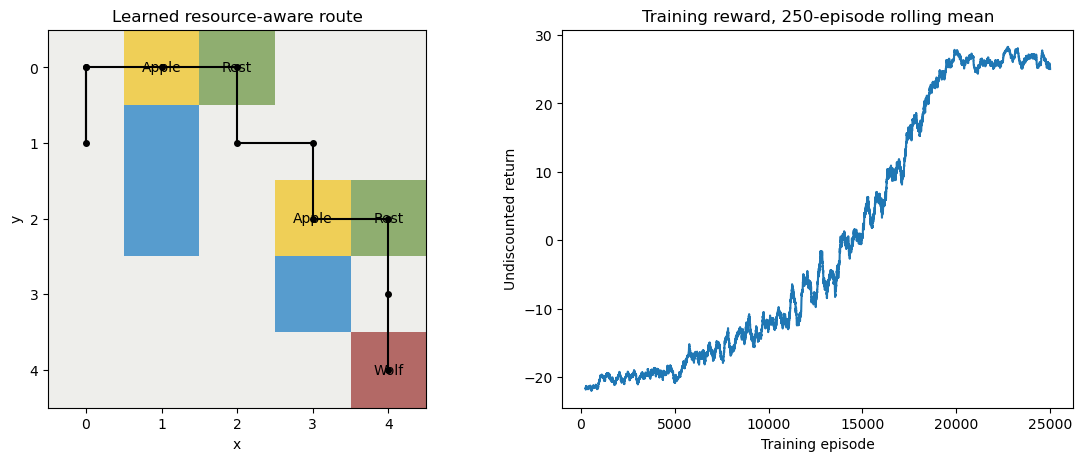

In [5]:
state=(0,0,6,0,3)
path=[state]
for _ in range(100):
    state,reward,done,outcome=world.step(state,int(np.argmax(q[state])))
    path.append(state)
    if done: break
print('Greedy route from the origin:',outcome)
display(pd.DataFrame(path,columns=['x','y','energy','fatigue','apples_mask']))
assert outcome=='won'
board=np.zeros((5,5))
for x,y in world.WATER: board[y,x]=1
for x,y in world.REST: board[y,x]=2
for x,y in world.APPLES: board[y,x]=3
board[world.WOLF[1],world.WOLF[0]]=4
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
axes[0].imshow(board,cmap=ListedColormap(['#eeeeeb','#579cce','#8fae70','#efcf57','#b36966']),vmin=0,vmax=4)
for x,y in world.APPLES: axes[0].text(x,y,'Apple',ha='center',va='center',fontsize=10)
for x,y in world.REST: axes[0].text(x,y,'Rest',ha='center',va='center',fontsize=10)
axes[0].text(*world.WOLF,'Wolf',ha='center',va='center',fontsize=10)
axes[0].plot([point[0] for point in path],[point[1] for point in path],'-o',color='black',markersize=4)
axes[0].set(title='Learned resource-aware route',xlabel='x',ylabel='y',xticks=range(5),yticks=range(5))
pd.Series(resource_training).rolling(250,min_periods=250).mean().plot(ax=axes[1])
axes[1].set(title='Training reward, 250-episode rolling mean',xlabel='Training episode',ylabel='Undiscounted return')
fig.savefig('resource-world.png',dpi=150)
plt.show()

## Challenge and limitations

Equal Q values do not by themselves make deterministic `argmax` a random
walk: ties need random selection or exploration. Epsilon is explicitly the
probability of a random exploratory action here, which is the reverse of
the original Gym lesson's epsilon convention. The shared update removes
bootstrapping on terminal transitions. The resource notebook retains
random and learned evaluation records and a full greedy route.

A position-only policy cannot distinguish a well-rested visitor from an
exhausted one, or know whether an apple remains. The expanded state fixes
that omission. Evaluation reuses this fixed map with controlled starting
positions; repeated runs do not establish generalization to new layouts.